In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")
print("Project location:", Path.cwd())

: 

In [ ]:

python -m pip install ipykernel pandas matplotlib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")
print("Project location:", Path.cwd())

Libraries imported successfully!
Project location: c:\Users\NHA MY\Downloads\archive


In [2]:

from pathlib import Path

project_folder = Path.cwd()

csv_files = list(project_folder.rglob("*.csv"))

print("Number of CSV files found:", len(csv_files))

for file in csv_files:
    print(file)
    

Number of CSV files found: 9
c:\Users\NHA MY\Downloads\archive\olist_customers_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_geolocation_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_orders_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_order_items_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_order_payments_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_order_reviews_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_products_dataset.csv
c:\Users\NHA MY\Downloads\archive\olist_sellers_dataset.csv
c:\Users\NHA MY\Downloads\archive\product_category_name_translation.csv


In [3]:

def find_csv(filename):
    matches = list(project_folder.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"Cannot find {filename}. Check your data folder."
        )

    return matches[0]


orders = pd.read_csv(
    find_csv("olist_orders_dataset.csv")
)

order_items = pd.read_csv(
    find_csv("olist_order_items_dataset.csv")
)

products = pd.read_csv(
    find_csv("olist_products_dataset.csv")
)

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)

Orders: (99441, 8)
Order items: (112650, 7)
Products: (32951, 9)


In [4]:

display(orders.head())

print("Orders columns:")
print(orders.columns.tolist())

print("\nMissing values in orders:")
print(orders.isnull().sum())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Missing values in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [5]:

print("Order status distribution:")
print(orders["order_status"].value_counts(dropna=False))

print("\nDuplicate order IDs:")
print(orders["order_id"].duplicated().sum())

print("\nDuplicate order-item records:")
print(order_items.duplicated().sum())

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Duplicate order IDs:
0

Duplicate order-item records:
0


In [6]:

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print(orders["order_purchase_timestamp"].dtype)

print(
    "Missing purchase timestamps:",
    orders["order_purchase_timestamp"].isna().sum()
)

datetime64[us]
Missing purchase timestamps: 0


In [7]:

print(order_items[["order_id", "product_id", "price"]].head())

print("\nMissing values:")
print(order_items[["order_id", "product_id", "price"]].isna().sum())

print("\nProduct price summary:")
print(order_items["price"].describe())

                           order_id                        product_id   price
0  00010242fe8c5a6d1ba2dd792cb16214  4244733e06e7ecb4970a6e2683c13e61   58.90
1  00018f77f2f0320c557190d7a144bdd3  e5f2d52b802189ee658865ca93d83a8f  239.90
2  000229ec398224ef6ca0657da4fc703e  c777355d18b72b67abbeef9df44fd0fd  199.00
3  00024acbcdf0a6daa1e931b038114c75  7634da152a4610f1595efa32f14722fc   12.99
4  00042b26cf59d7ce69dfabb4e55b4fd9  ac6c3623068f30de03045865e4e10089  199.90

Missing values:
order_id      0
product_id    0
price         0
dtype: int64

Product price summary:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64


In [8]:

# Copy data to keep the original table unchanged
sales = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Remove records without a valid purchase date
sales = sales.dropna(subset=["order_purchase_timestamp"]).copy()

# Extract month
sales["month"] = (
    sales["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly product revenue
monthly_revenue = (
    sales.groupby("month", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "product_revenue"})
)

display(monthly_revenue.head(10))

,month,product_revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02
5,2017-03,374344.30
6,2017-04,359927.23
7,2017-05,506071.14
8,2017-06,433038.60
9,2017-07,498031.48


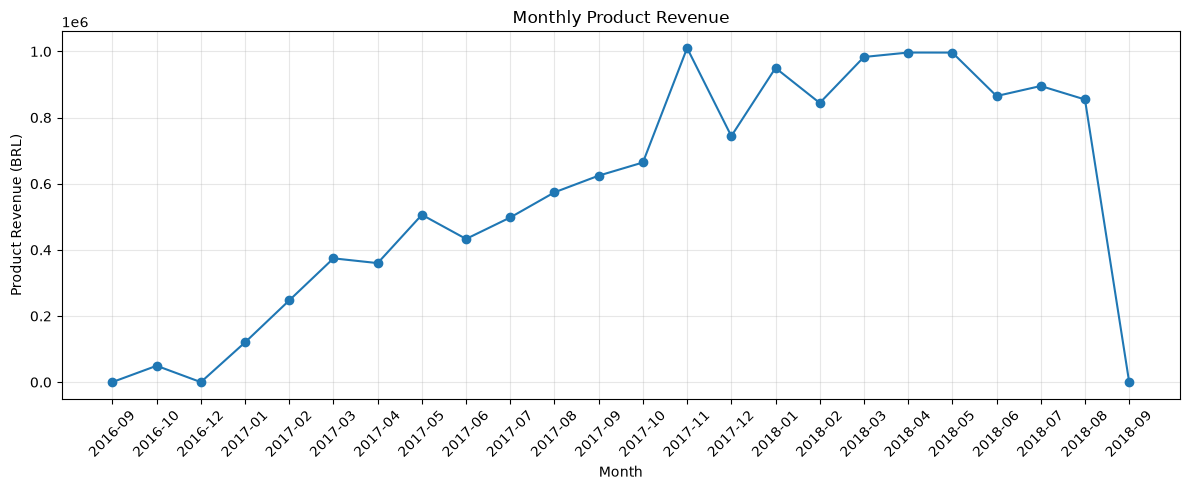

In [9]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["month"].astype(str),
    monthly_revenue["product_revenue"],
    marker="o"
)

plt.title("Monthly Product Revenue")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:

# 1. Find the highest and lowest revenue months
highest_month = monthly_revenue.loc[
    monthly_revenue["product_revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["product_revenue"].idxmin()
]

print("Highest revenue month:")
print(highest_month)

print("\nLowest revenue month:")
print(lowest_month)

# 2. Inspect the last 6 months
print("\nLast 6 months of product revenue:")
display(monthly_revenue.tail(6))


Highest revenue month:
month                 2017-11
product_revenue    1010271.37
Name: 13, dtype: object

Lowest revenue month:
month              2016-12
product_revenue       10.9
Name: 2, dtype: object

Last 6 months of product revenue:


,month,product_revenue
18,2018-04,996647.75
19,2018-05,996517.68
20,2018-06,865124.31
21,2018-07,895507.22
22,2018-08,854686.33
23,2018-09,145.00


In [11]:

# Check the date range in the original orders table
print(
    "First purchase date:",
    orders["order_purchase_timestamp"].min()
)

print(
    "Last purchase date:",
    orders["order_purchase_timestamp"].max()
)

# Count order items by month
monthly_orders = (
    sales.groupby("month")
    .agg(
        order_count=("order_id", "nunique"),
        item_count=("order_id", "size"),
        product_revenue=("price", "sum")
    )
    .reset_index()
)

display(monthly_orders.tail(6))

First purchase date: 2016-09-04 21:15:19
Last purchase date: 2018-10-17 17:30:18


,month,order_count,item_count,product_revenue
18,2018-04,6934,7975,996647.75
19,2018-05,6853,7925,996517.68
20,2018-06,6160,7078,865124.31
21,2018-07,6273,7092,895507.22
22,2018-08,6452,7248,854686.33
23,2018-09,1,1,145.00


In [12]:

category_translation = pd.read_csv(
    find_csv("product_category_name_translation.csv")
)

print("Translation table shape:", category_translation.shape)

display(category_translation.head())

Translation table shape: (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [13]:

# Attach product categories to each order item
product_sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Translate category names into English
product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Handle products without a translated category
product_sales["product_category_name_english"] = (
    product_sales["product_category_name_english"]
    .fillna("unknown_or_untranslated")
)

print("Rows in order_items:", len(order_items))
print("Rows after merging:", len(product_sales))

display(
    product_sales[
        ["product_id", "price", "product_category_name_english"]
    ].head()
)

Rows in order_items: 112650
Rows after merging: 112650


,product_id,price,product_category_name_english
0,4244733e06e7ecb4970a6e2683c13e61,58.90,cool_stuff
1,e5f2d52b802189ee658865ca93d83a8f,239.90,pet_shop
2,c777355d18b72b67abbeef9df44fd0fd,199.00,furniture_decor
3,7634da152a4610f1595efa32f14722fc,12.99,perfumery
4,ac6c3623068f30de03045865e4e10089,199.90,garden_tools


In [14]:

category_revenue = (
    product_sales
    .groupby("product_category_name_english", as_index=False)
    .agg(
        product_revenue=("price", "sum"),
        item_count=("order_id", "size")
    )
    .sort_values("product_revenue", ascending=False)
)

display(category_revenue.head(10))


,product_category_name_english,product_revenue,item_count
43,health_beauty,1258681.34,9670
71,watches_gifts,1205005.68,5991
7,bed_bath_table,1036988.68,11115
65,sports_leisure,988048.97,8641
15,computers_accessories,911954.32,7827
39,furniture_decor,729762.49,8334
20,cool_stuff,635290.85,3796
49,housewares,632248.66,6964
5,auto,592720.11,4235
42,garden_tools,485256.46,4347


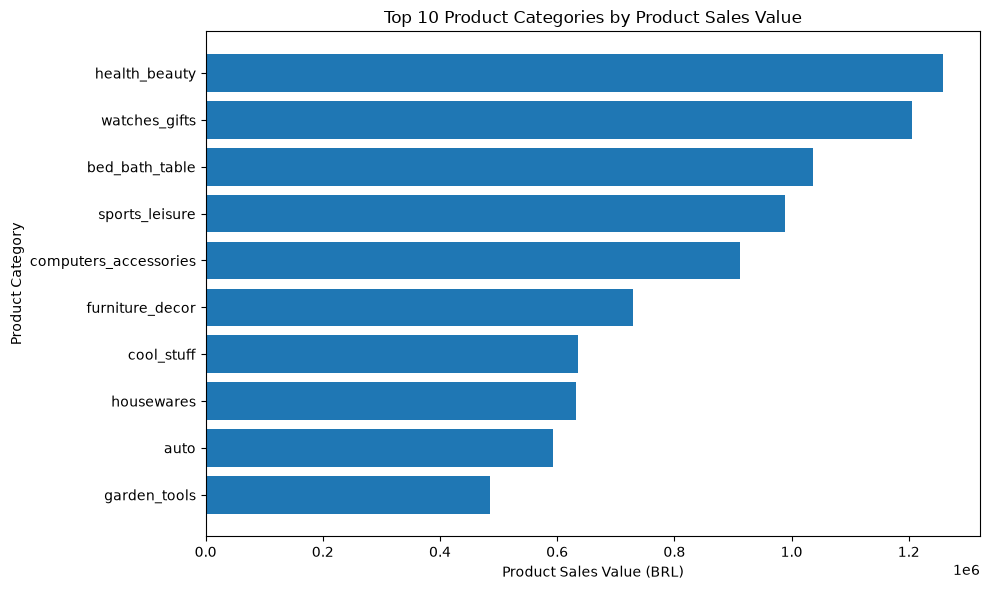

In [15]:

top_categories = category_revenue.head(10).sort_values(
    "product_revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["product_category_name_english"],
    top_categories["product_revenue"]
)

plt.title("Top 10 Product Categories by Product Sales Value")
plt.xlabel("Product Sales Value (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [16]:

# Summarize sales performance by product category
category_analysis = (
    product_sales
    .groupby("product_category_name_english")
    .agg(
        product_revenue=("price", "sum"),
        number_of_orders=("order_id", "nunique"),
        number_of_items=("order_id", "size"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

# Calculate each category's share of total product revenue
total_revenue = category_analysis["product_revenue"].sum()

category_analysis["revenue_share_pct"] = (
    category_analysis["product_revenue"]
    / total_revenue * 100
)

# Rank categories by product revenue
category_analysis = category_analysis.sort_values(
    "product_revenue",
    ascending=False
)

display(
    category_analysis.head(10).round(2)
)

,product_category_name_english,product_revenue,number_of_orders,number_of_items,average_item_price,revenue_share_pct
43,health_beauty,1258681.34,8836,9670,130.16,9.26
71,watches_gifts,1205005.68,5624,5991,201.14,8.87
7,bed_bath_table,1036988.68,9417,11115,93.30,7.63
65,sports_leisure,988048.97,7720,8641,114.34,7.27
15,computers_accessories,911954.32,6689,7827,116.51,6.71
39,furniture_decor,729762.49,6449,8334,87.56,5.37
20,cool_stuff,635290.85,3632,3796,167.36,4.67
49,housewares,632248.66,5884,6964,90.79,4.65
5,auto,592720.11,3897,4235,139.96,4.36
42,garden_tools,485256.46,3518,4347,111.63,3.57


In [17]:

top_10_share = category_analysis.head(10)["revenue_share_pct"].sum()

print(f"Top 10 category revenue share: {top_10_share:.2f}%")

Top 10 category revenue share: 62.36%


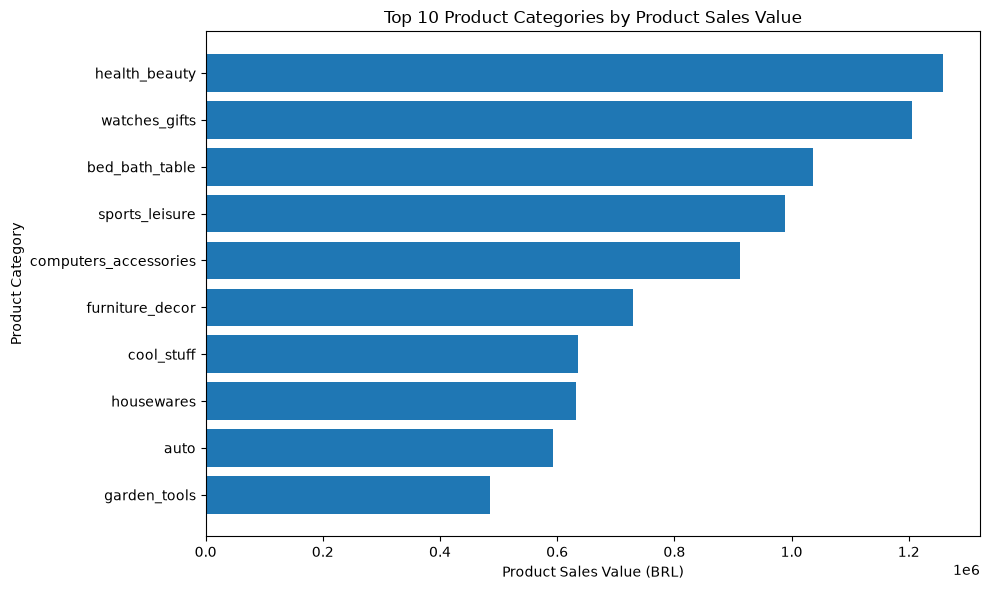

Chart saved to: outputs\top_10_categories.png


In [18]:

from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

# Save the category revenue chart
top_categories = category_analysis.head(10).sort_values(
    "product_revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["product_category_name_english"],
    top_categories["product_revenue"]
)

plt.title("Top 10 Product Categories by Product Sales Value")
plt.xlabel("Product Sales Value (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    output_folder / "top_10_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", output_folder / "top_10_categories.png")

In [19]:

# Select the top 10 categories
top10_analysis = category_analysis.head(10).copy()

# Display the key metrics
display(
    top10_analysis[
        [
            "product_category_name_english",
            "product_revenue",
            "number_of_orders",
            "number_of_items",
            "average_item_price",
            "revenue_share_pct"
        ]
    ].round(2)
)

,product_category_name_english,product_revenue,number_of_orders,number_of_items,average_item_price,revenue_share_pct
43,health_beauty,1258681.34,8836,9670,130.16,9.26
71,watches_gifts,1205005.68,5624,5991,201.14,8.87
7,bed_bath_table,1036988.68,9417,11115,93.30,7.63
65,sports_leisure,988048.97,7720,8641,114.34,7.27
15,computers_accessories,911954.32,6689,7827,116.51,6.71
39,furniture_decor,729762.49,6449,8334,87.56,5.37
20,cool_stuff,635290.85,3632,3796,167.36,4.67
49,housewares,632248.66,5884,6964,90.79,4.65
5,auto,592720.11,3897,4235,139.96,4.36
42,garden_tools,485256.46,3518,4347,111.63,3.57


In [20]:

# Display selected columns without horizontal scrolling
columns_to_show = [
    "product_category_name_english",
    "product_revenue",
    "number_of_orders",
    "number_of_items",
    "average_item_price",
    "revenue_share_pct"
]

display(
    category_analysis.head(10)[columns_to_show].round(2)
)

,product_category_name_english,product_revenue,number_of_orders,number_of_items,average_item_price,revenue_share_pct
43,health_beauty,1258681.34,8836,9670,130.16,9.26
71,watches_gifts,1205005.68,5624,5991,201.14,8.87
7,bed_bath_table,1036988.68,9417,11115,93.30,7.63
65,sports_leisure,988048.97,7720,8641,114.34,7.27
15,computers_accessories,911954.32,6689,7827,116.51,6.71
39,furniture_decor,729762.49,6449,8334,87.56,5.37
20,cool_stuff,635290.85,3632,3796,167.36,4.67
49,housewares,632248.66,5884,6964,90.79,4.65
5,auto,592720.11,3897,4235,139.96,4.36
42,garden_tools,485256.46,3518,4347,111.63,3.57


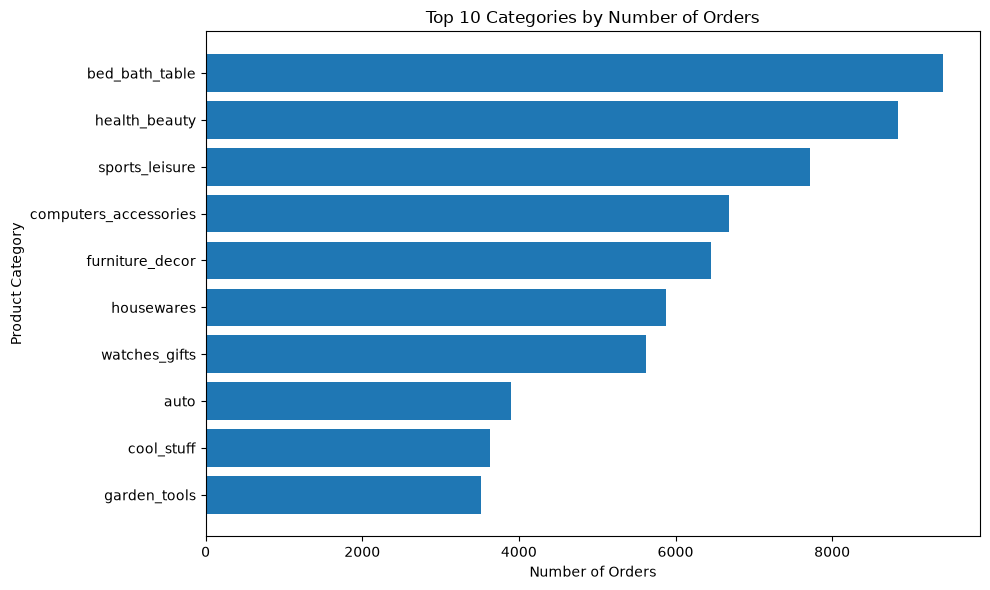

In [21]:

top_orders = (
    category_analysis.head(10)
    .sort_values("number_of_orders", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_orders["product_category_name_english"],
    top_orders["number_of_orders"]
)

plt.title("Top 10 Categories by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    output_folder / "top_10_categories_by_orders.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

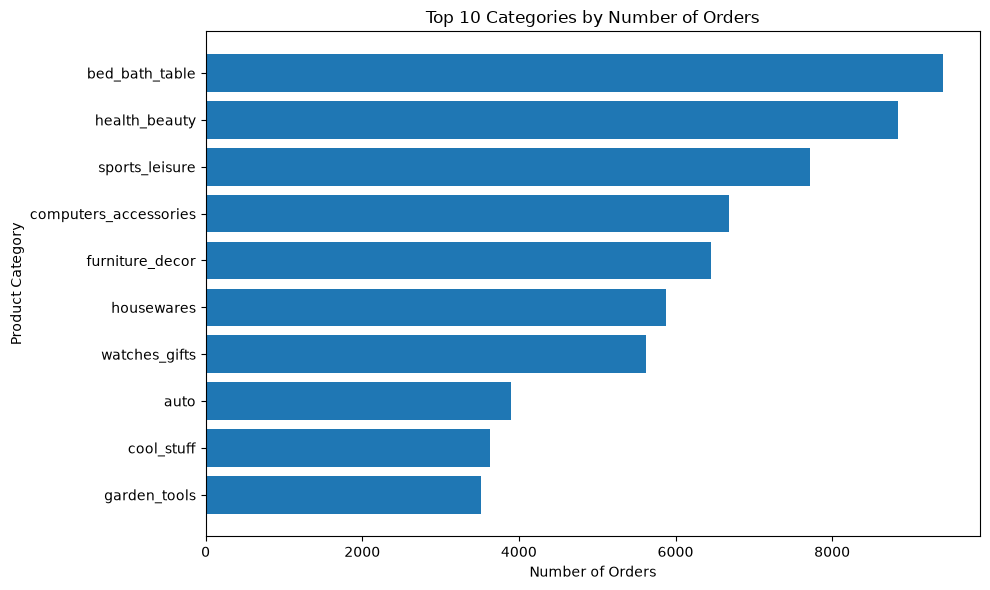

In [22]:

top_orders = (
    category_analysis.head(10)
    .sort_values("number_of_orders", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_orders["product_category_name_english"],
    top_orders["number_of_orders"]
)

plt.title("Top 10 Categories by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    output_folder / "top_10_categories_by_orders.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()